# Mobile Price Classification - Project Implementation
**Goal:** predict a phone's price range (0 = low, 1 = medium, 2 = high, 3 = very high) from its specifications.

**Dataset:** [Kaggle - Mobile Price Classification](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification). Put `train.csv` and `test.csv` in `data/raw/`.

**Workflow:** 1. Load -> 2. EDA -> 3. Preprocess -> 4. Train & compare models -> 5. Evaluate -> 6. Predict on unlabelled data

The notebook reuses the modules in `src/`, so results match `python run_pipeline.py`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))          # make `src` importable
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from src.utils import load_config, resolve
from src import preprocess, train, evaluate, predict

sns.set_theme(style="whitegrid")
cfg = load_config()
TARGET = cfg["target"]

## 1. Load data

In [2]:
df = pd.read_csv(resolve(cfg["data"]["raw_path"]))
print(df.shape)
df.head()

(2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


## 2. Exploratory data analysis

In [4]:
print("Missing values:", df.isna().sum().sum(), "| Duplicates:", df.duplicated().sum())
df[TARGET].value_counts().sort_index().plot.bar(color="steelblue", title="Target distribution (balanced classes)")
plt.xlabel("price_range"); plt.show()

Missing values: 0 | Duplicates: 0


In [5]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation matrix"); plt.show()
print(df.corr()[TARGET].drop(TARGET).sort_values(ascending=False).head(8))

ram              0.917046
battery_power    0.200723
px_width         0.165818
px_height        0.148858
int_memory       0.044435
sc_w             0.038711
pc               0.033599
three_g          0.023611
Name: price_range, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["ram", "battery_power", "px_width"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax)
    ax.set_title(f"{col} by price_range")
plt.tight_layout(); plt.show()

**Observation:** `ram` is by far the strongest predictor of price range; battery power and pixel resolution follow.

## 3. Preprocessing & feature engineering

In [7]:
clean = preprocess.validate(df, TARGET)
clean = preprocess.engineer_features(clean)
train_df, test_df = preprocess.split_and_save(clean, cfg)
print(train_df.shape, test_df.shape)
train_df.head()

2026-10-10 21:07:36,402 | INFO | preprocess | Saved processed data: train (1600, 26), test (400, 26) -> C:\Users\pchar\Desktop\my project\data\processed


(1600, 26) (400, 26)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,talk_time,three_g,touch_screen,wifi,px_area,screen_area,px_density,camera_total,ram_per_core,price_range
469,1845,1,0.5,1,10,0,61,0.3,96,1,...,6,0,0,0,202940,45,4411.739130,22,1731.000000,1
565,1271,1,0.5,0,12,0,32,0.1,113,7,...,14,0,0,1,2631150,210,12469.905213,27,63.571429,0
396,788,0,2.5,1,4,1,57,0.9,91,8,...,6,1,1,1,48762,96,502.701031,16,496.125000,3
452,1406,0,0.5,1,2,1,34,0.8,98,3,...,2,1,0,1,1389222,72,19030.438356,7,1305.000000,3
325,920,0,2.1,1,5,0,25,0.4,115,7,...,5,0,1,1,225302,70,3173.267606,19,112.142857,0


## 4. Model training & comparison (cross-validated grid search)

In [8]:
best_name, comparison = train.run()
comparison

2026-10-10 21:07:36,452 | INFO | train | Training on 1600 rows, 25 features
2026-10-10 21:07:41,461 | INFO | train | logistic_regression  CV accuracy = 0.9569  params={'clf__C': 10}
2026-10-10 21:07:41,891 | INFO | train | svc                  CV accuracy = 0.9594  params={'clf__C': 10, 'clf__kernel': 'linear'}
2026-10-10 21:07:42,273 | INFO | train | knn                  CV accuracy = 0.5613  params={'clf__n_neighbors': 15}
2026-10-10 21:07:45,620 | INFO | train | random_forest        CV accuracy = 0.8644  params={'clf__max_depth': 10, 'clf__n_estimators': 400}
2026-10-10 21:08:00,162 | INFO | train | gradient_boosting    CV accuracy = 0.8944  params={'clf__learning_rate': 0.05, 'clf__n_estimators': 200}
2026-10-10 21:08:00,191 | INFO | train | Best model: svc (CV 0.9594) saved to C:\Users\pchar\Desktop\my project\models


,model,cv_accuracy,best_params
1,svc,0.9594,"{""clf__C"": 10, ""clf__kernel"": ""linear""}"
0,logistic_regression,0.9569,"{""clf__C"": 10}"
4,gradient_boosting,0.8944,"{""clf__learning_rate"": 0.05, ""clf__n_estimator..."
3,random_forest,0.8644,"{""clf__max_depth"": 10, ""clf__n_estimators"": 400}"
2,knn,0.5612,"{""clf__n_neighbors"": 15}"


In [9]:
comparison.plot.barh(x="model", y="cv_accuracy", legend=False, color="steelblue", figsize=(7, 3.5))
plt.xlabel("CV accuracy"); plt.title("Model comparison"); plt.show()

## 5. Evaluation on the held-out test set

In [10]:
metrics = evaluate.run()
metrics

2026-10-10 21:08:01,063 | INFO | evaluate | Test metrics: {'model': 'svc', 'cv_score': 0.9594, 'test_accuracy': 0.97, 'precision_macro': 0.9703, 'recall_macro': 0.97, 'f1_macro': 0.97}


{'model': 'svc',
 'cv_score': 0.9594,
 'test_accuracy': 0.97,
 'precision_macro': 0.9703,
 'recall_macro': 0.97,
 'f1_macro': 0.97}

In [11]:
print(open(resolve("reports/classification_report.txt")).read())

               precision    recall  f1-score   support

      Low (0)       0.98      0.99      0.99       100
   Medium (1)       0.98      0.94      0.96       100
     High (2)       0.94      0.97      0.96       100
Very High (3)       0.98      0.98      0.98       100

     accuracy                           0.97       400
    macro avg       0.97      0.97      0.97       400
 weighted avg       0.97      0.97      0.97       400



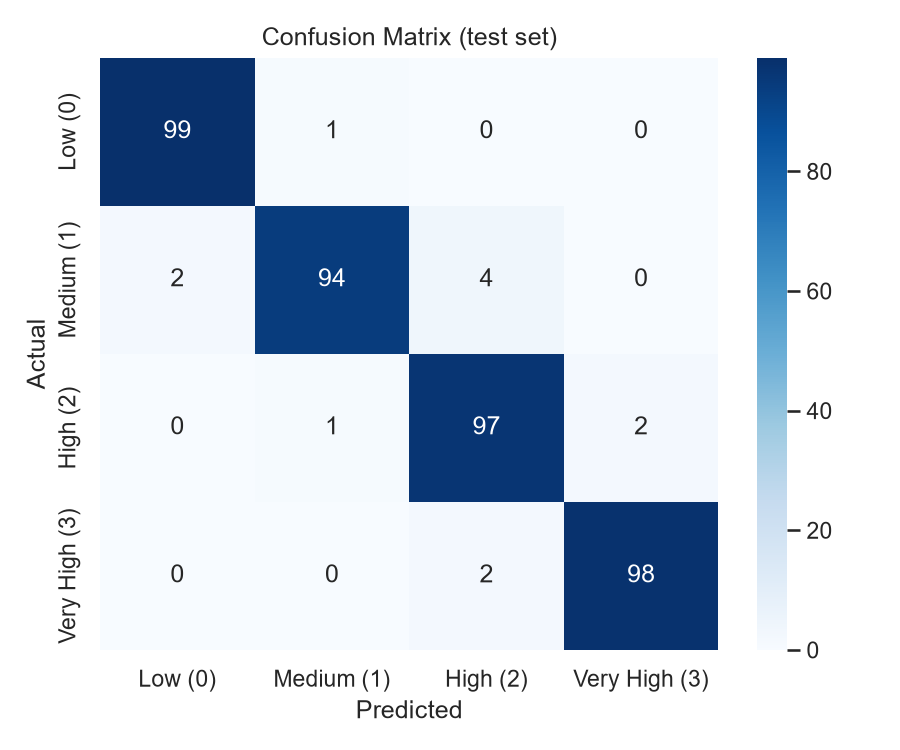

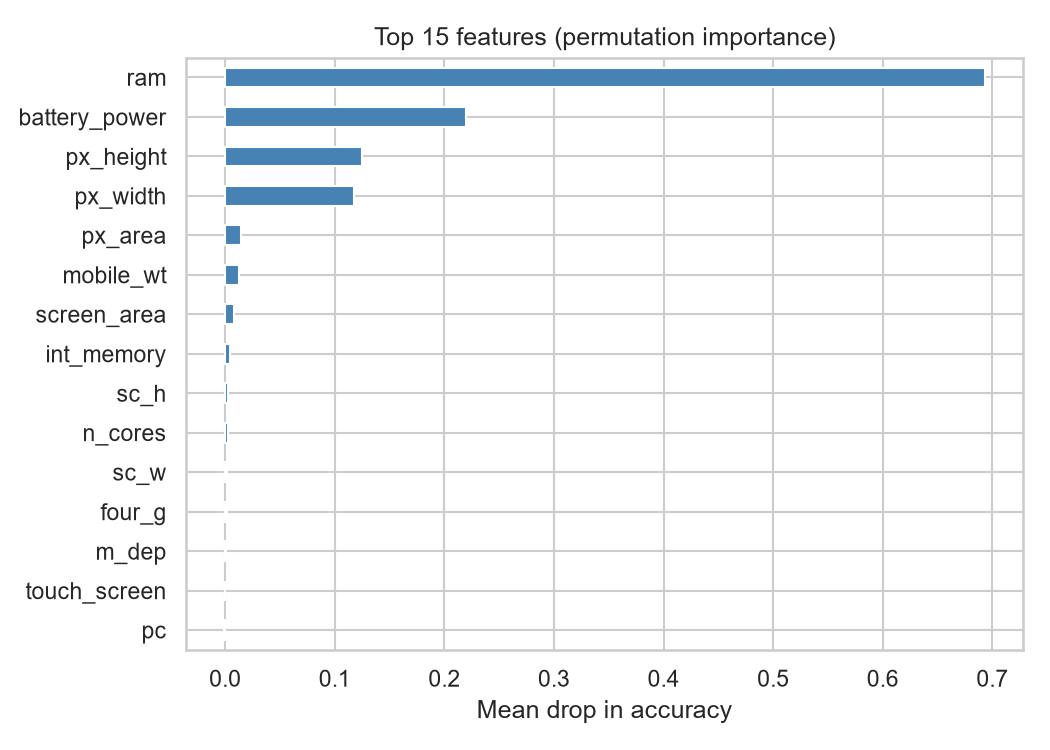

In [12]:
from IPython.display import Image, display
display(Image(filename=str(resolve("outputs/confusion_matrix.png"))))
display(Image(filename=str(resolve("outputs/feature_importance.png"))))

## 6. Predict on unlabelled data (`test.csv`)

In [13]:
preds = predict.run()
print(preds["predicted_price_range"].value_counts().sort_index())
preds.head()

2026-10-10 21:08:01,181 | INFO | predict | Saved 1000 predictions to C:\Users\pchar\Desktop\my project\outputs\predictions.csv


predicted_price_range
0    256
1    227
2    262
3    255
Name: count, dtype: int64


,id,predicted_price_range
0,1,2
1,2,3
2,3,2
3,4,3
4,5,1


## 7. Conclusions
- Classes are perfectly balanced, there are no missing values, so no resampling/imputation is needed.
- `ram` dominates; engineered features (pixel density, total camera MP, RAM per core) add small extra signal.
- Linear models (Logistic Regression / SVC) and ensembles all perform strongly - the best one is saved to `models/best_model.joblib`.
- **Next steps:** try XGBoost/LightGBM, calibrate probabilities, wrap prediction in an API (FastAPI) or Streamlit app.